In [ ]:
from google.colab import files

uploaded = files.upload()

Saving training_set_balanced.csv to training_set_balanced.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving validation_set.csv to validation_set.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving test_set.csv to test_set.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving single_obfuscation_attacks.csv to single_obfuscation_attacks.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving multi_obfuscation_attacks.csv to multi_obfuscation_attacks.csv


import libraries

In [ ]:
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
train_df = pd.read_csv("training_set_balanced.csv")
val_df = pd.read_csv("validation_set.csv")
test_df = pd.read_csv("test_set.csv")

single_df = pd.read_csv("single_obfuscation_attacks.csv")
multi_df = pd.read_csv("multi_obfuscation_attacks.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Clean test:", test_df.shape)
print("Single obfuscation:", single_df.shape)
print("Multi obfuscation:", multi_df.shape)

Train: (65307, 5)
Validation: (22771, 5)
Clean test: (22777, 5)
Single obfuscation: (42749, 10)
Multi obfuscation: (7872, 11)


In [ ]:
TEXT_COL = "text"
LABEL_COL = "abusive"

In [ ]:
label_map = {
    "NOT": 0,
    "OFF": 1
}

for df in [train_df, val_df, test_df, single_df, multi_df]:
    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
    df["label"] = df[LABEL_COL].map(label_map)

In [ ]:
print(train_df["label"].value_counts())
print(train_df[[TEXT_COL, LABEL_COL, "label"]].head())

label
0    43538
1    21769
Name: count, dtype: int64
                                                text abusive  label
0  Yes.  Also mentioned by New Scientist here:www...     NOT      0
1  == Requested move == \n\n  \n\n :2014 South Ko...     NOT      0
2  What THE FUCK? \n\nRestore the Code lyoko 2 Ar...     OFF      1
3    <user> fuck you and your anti white blood libel     OFF      1
4             pure bullshit. The Dissident Aggressor     OFF      1


In [ ]:
#build character vocab
from tensorflow.keras.layers import TextVectorization

MAX_LENGTH = 280

char_vectorizer = TextVectorization(
    standardize=None,
    split="character",
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

char_vectorizer.adapt(train_df[TEXT_COL].values)

In [ ]:
#inspect cnn vocab
vocab = char_vectorizer.get_vocabulary()

VOCAB_SIZE = len(vocab)

print("Character vocabulary size:", VOCAB_SIZE)
print(vocab[:100])

Character vocabulary size: 2018
['', '[UNK]', np.str_(' '), np.str_('e'), np.str_('t'), np.str_('a'), np.str_('o'), np.str_('i'), np.str_('n'), np.str_('s'), np.str_('r'), np.str_('h'), np.str_('l'), np.str_('d'), np.str_('u'), np.str_('c'), np.str_('m'), np.str_('y'), np.str_('g'), np.str_('p'), np.str_('f'), np.str_('w'), np.str_('.'), np.str_('b'), np.str_('k'), np.str_('v'), np.str_('\n'), np.str_('I'), np.str_(','), np.str_('"'), np.str_('T'), np.str_('S'), np.str_("'"), np.str_('E'), np.str_('A'), np.str_('R'), np.str_(':'), np.str_('='), np.str_('!'), np.str_('U'), np.str_('O'), np.str_('C'), np.str_('W'), np.str_('N'), np.str_('H'), np.str_('?'), np.str_('P'), np.str_('D'), np.str_('Y'), np.str_('M'), np.str_('L'), np.str_('1'), np.str_('j'), np.str_('F'), np.str_('0'), np.str_('B'), np.str_('x'), np.str_('G'), np.str_('2'), np.str_('-'), np.str_('@'), np.str_(')'), np.str_('z'), np.str_('('), np.str_('K'), np.str_('/'), np.str_('>'), np.str_('J'), np.str_('q'), np.str_('3'), n

convert datasets

In [ ]:
X_train = train_df[TEXT_COL].values
y_train = train_df["label"].values

X_val = val_df[TEXT_COL].values
y_val = val_df["label"].values

X_test = test_df[TEXT_COL].values
y_test = test_df["label"].values

build character-level cnn

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout
)

EMBEDDING_DIM = 64
FILTERS = 128
KERNEL_SIZE = 5

cnn_model = Sequential([

    Input(shape=(1,), dtype=tf.string),

    char_vectorizer,

    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM
    ),

    Conv1D(
        filters=FILTERS,
        kernel_size=KERNEL_SIZE,
        activation="relu"
    ),

    GlobalMaxPooling1D(),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.5),

    Dense(
        1,
        activation="sigmoid"
    )
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 280)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 280, 64)        │       129,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 276, 128)       │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,561 (697.50 KB)

 Trainable params: 178,561 (697.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [ ]:
#early stopping
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

train cnn

In [ ]:
history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
511/511 ━━━━━━━━━━━━━━━━━━━━ 154s 296ms/step - accuracy: 0.7951 - loss: 0.4295 - precision: 0.7156 - recall: 0.6395 - val_accuracy: 0.8549 - val_loss: 0.2845 - val_precision: 0.4391 - val_recall: 0.7732
Epoch 2/10
511/511 ━━━━━━━━━━━━━━━━━━━━ 155s 303ms/step - accuracy: 0.8388 - loss: 0.3467 - precision: 0.7425 - recall: 0.7908 - val_accuracy: 0.8628 - val_loss: 0.2655 - val_precision: 0.4574 - val_recall: 0.7967
Epoch 3/10
511/511 ━━━━━━━━━━━━━━━━━━━━ 155s 303ms/step - accuracy: 0.8516 - loss: 0.3206 - precision: 0.7627 - recall: 0.8051 - val_accuracy: 0.8575 - val_loss: 0.2775 - val_precision: 0.4483 - val_recall: 0.8375
Epoch 4/10
511/511 ━━━━━━━━━━━━━━━━━━━━ 192s 284ms/step - accuracy: 0.8597 - loss: 0.3016 - precision: 0.7751 - recall: 0.8159 - val_accuracy: 0.8662 - val_loss: 0.2635 - val_precision: 0.4657 - val_recall: 0.8140
Epoch 5/10
511/511 ━━━━━━━━━━━━━━━━━━━━ 155s 304ms/step - accuracy: 0.8681 - loss: 0.2860 - precision: 0.7872 - recall: 0.8284 - val_accuracy: 0

plot training performance

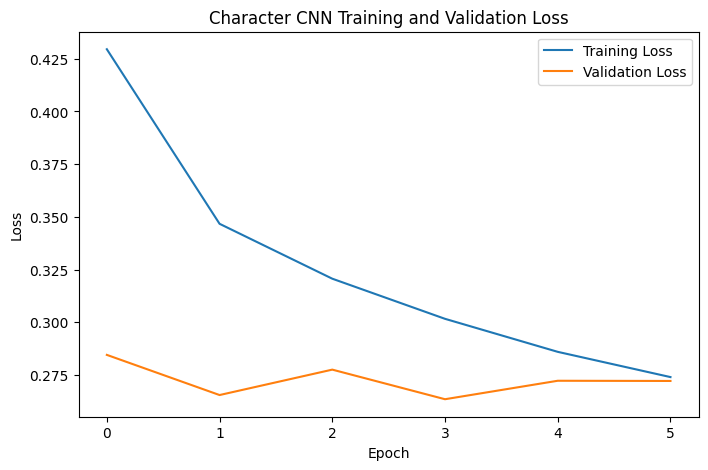

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Character CNN Training and Validation Loss")

plt.legend()
plt.show()

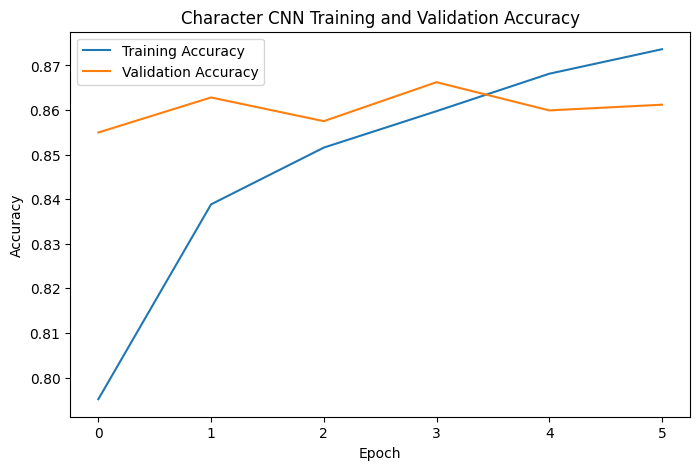

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Character CNN Training and Validation Accuracy")

plt.legend()
plt.show()

reusable cnn evaluation function

In [ ]:
def evaluate_cnn(model, df, text_col=TEXT_COL, label_col="label"):

    X = df[text_col].fillna("").astype(str).values
    y_true = df[label_col].values

    probabilities = model.predict(
        X,
        batch_size=256,
        verbose=0
    ).ravel()

    y_pred = (probabilities >= 0.5).astype(int)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        )
    }

evaluate cnn on clean set

In [ ]:
cnn_clean_metrics = evaluate_cnn(
    cnn_model,
    test_df
)

cnn_clean_metrics

{'accuracy': 0.8632831364973438,
 'precision': 0.4589716684155299,
 'recall': 0.8031582813073815,
 'f1': 0.5841346153846154}

evaluate single obfuscation attacks

In [ ]:
cnn_single_metrics = evaluate_cnn(
    cnn_model,
    single_df,
    text_col="obfuscated_text"
)

cnn_single_metrics

{'accuracy': 0.6355938150600015,
 'precision': 1.0,
 'recall': 0.6355938150600015,
 'f1': 0.7772025171624714}

evaluate multi-obfuscation attacks

In [ ]:
cnn_multi_metrics = evaluate_cnn(
    cnn_model,
    multi_df,
    text_col="obfuscated_text"
)

cnn_multi_metrics

{'accuracy': 0.45452235772357724,
 'precision': 1.0,
 'recall': 0.45452235772357724,
 'f1': 0.6249781659388647}

robustness drop

In [ ]:
cnn_single_drop = (
    cnn_clean_metrics["f1"]
    - cnn_single_metrics["f1"]
)

cnn_multi_drop = (
    cnn_clean_metrics["f1"]
    - cnn_multi_metrics["f1"]
)

print("CNN clean F1:", cnn_clean_metrics["f1"])
print("CNN single F1:", cnn_single_metrics["f1"])
print("CNN single ΔF1:", cnn_single_drop)

print()

print("CNN multi F1:", cnn_multi_metrics["f1"])
print("CNN multi ΔF1:", cnn_multi_drop)

CNN clean F1: 0.5841346153846154
CNN single F1: 0.7772025171624714
CNN single ΔF1: -0.19306790177785593

CNN multi F1: 0.6249781659388647
CNN multi ΔF1: -0.040843550554249264


evaluate severity

In [ ]:
print(single_df.columns.tolist())
print(single_df["severity"].value_counts())

['id', 'text', 'text_length', 'source_dataset', 'abusive', 'original_text', 'obfuscated_text', 'obfuscation_type', 'severity', 'obfuscated_length', 'label']
severity
low       13473
medium    13360
high      13193
none       2723
Name: count, dtype: int64


In [ ]:
cnn_severity_results = []

for severity in sorted(single_df["severity"].dropna().unique()):

    subset = single_df[
        single_df["severity"] == severity
    ]

    metrics = evaluate_cnn(
        cnn_model,
        subset,
        text_col="obfuscated_text"
    )

    cnn_severity_results.append({
        "model": "Character CNN",
        "attack_type": "single",
        "severity": severity,
        **metrics,
        "f1_drop": cnn_clean_metrics["f1"] - metrics["f1"]
    })

cnn_severity_df = pd.DataFrame(cnn_severity_results)

cnn_severity_df

,model,attack_type,severity,accuracy,precision,recall,f1,f1_drop
0,Character CNN,single,high,0.530660,1.0,0.530660,0.693374,-0.109240
1,Character CNN,single,low,0.707637,1.0,0.707637,0.828791,-0.244657
2,Character CNN,single,medium,0.632410,1.0,0.632410,0.774818,-0.190683
3,Character CNN,single,none,0.803158,1.0,0.803158,0.890835,-0.306700


In [ ]:
severity_order = ["low", "medium", "high"]

cnn_severity_df["severity"] = pd.Categorical(
    cnn_severity_df["severity"],
    categories=severity_order,
    ordered=True
)

cnn_severity_df = cnn_severity_df.sort_values("severity")

evaluate individual technqiues

In [ ]:
single_df.columns.tolist()

['id',
 'text',
 'text_length',
 'source_dataset',
 'abusive',
 'original_text',
 'obfuscated_text',
 'obfuscation_type',
 'severity',
 'obfuscated_length',
 'label']

In [ ]:
TECHNIQUE_COL = "obfuscation_type"

In [ ]:
cnn_technique_results = []

for technique in single_df[TECHNIQUE_COL].dropna().unique():

    subset = single_df[
        single_df[TECHNIQUE_COL] == technique
    ]

    metrics = evaluate_cnn(
        cnn_model,
        subset,
        text_col="obfuscated_text"
    )

    cnn_technique_results.append({
        "model": "Character CNN",
        "technique": technique,
        **metrics,
        "f1_drop":
            cnn_clean_metrics["f1"] -
            metrics["f1"]
    })

cnn_technique_df = pd.DataFrame(
    cnn_technique_results
)

cnn_technique_df.sort_values(
    "f1_drop",
    ascending=False
)

,model,technique,accuracy,precision,recall,f1,f1_drop
3,Character CNN,symbolic_masking,0.496144,1.0,0.496144,0.663230,-0.079096
5,Character CNN,unicode_confusable,0.599584,1.0,0.599584,0.749675,-0.165540
1,Character CNN,character_substitution,0.628596,1.0,0.628596,0.771948,-0.187814
2,Character CNN,spacing,0.692464,1.0,0.692464,0.818291,-0.234157
4,Character CNN,misspelling,0.711062,1.0,0.711062,0.831135,-0.247001
0,Character CNN,clean,0.803158,1.0,0.803158,0.890835,-0.306700


comparision of logistic, svm, cnn

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ml_overall_results.csv to ml_overall_results.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ml_severity_results.csv to ml_severity_results.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ml_single_obfuscation_results.csv to ml_single_obfuscation_results.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ml_multi_obfuscation_results.csv to ml_multi_obfuscation_results.csv


In [ ]:
import pandas as pd

ml_overall = pd.read_csv("ml_overall_results.csv")
ml_severity = pd.read_csv("ml_severity_results.csv")
ml_single = pd.read_csv("ml_single_obfuscation_results.csv")
ml_multi = pd.read_csv("ml_multi_obfuscation_results.csv")

print("Overall results:")
display(ml_overall)

print("Severity results:")
display(ml_severity)

print("Single-obfuscation results:")
display(ml_single.head())

print("Multi-obfuscation results:")
display(ml_multi)

Overall results:


,model,dataset,precision,recall,f1,f1_drop
0,Logistic Regression,Clean,0.421737,0.857877,0.565481,0.000000
1,Linear SVM,Clean,0.433353,0.817848,0.566523,0.000000
2,Logistic Regression,Single Obfuscation,1.000000,0.679338,0.809054,-0.243574
3,Linear SVM,Single Obfuscation,1.000000,0.661302,0.796125,-0.229602
4,Logistic Regression,Multi Obfuscation,1.000000,0.495173,0.662362,-0.096881
5,Linear SVM,Multi Obfuscation,1.000000,0.523120,0.686906,-0.120383


Severity results:


,model,n_samples,precision,recall,f1,severity,f1_drop
0,Logistic Regression,13193,1.0,0.539680,0.701029,high,-0.135548
1,Logistic Regression,13473,1.0,0.794181,0.885285,low,-0.319805
2,Logistic Regression,13360,1.0,0.665045,0.798831,medium,-0.233351
3,Logistic Regression,2723,1.0,0.857877,0.923503,none,-0.358022
4,Linear SVM,13193,1.0,0.531797,0.694344,high,-0.127822
5,Linear SVM,13473,1.0,0.758331,0.862558,low,-0.296036
6,Linear SVM,13360,1.0,0.659431,0.794768,medium,-0.228245
7,Linear SVM,2723,1.0,0.817848,0.899798,none,-0.333275


Single-obfuscation results:


,model,n_samples,precision,recall,f1,obfuscation_type,severity,f1_drop
0,Logistic Regression,2723,1.0,0.479251,0.647964,character_substitution,high,-0.082484
1,Logistic Regression,2723,1.0,0.803893,0.891287,character_substitution,low,-0.325806
2,Logistic Regression,2723,1.0,0.699596,0.823250,character_substitution,medium,-0.257769
3,Logistic Regression,2723,1.0,0.857877,0.923503,clean,none,-0.358022
4,Logistic Regression,2717,1.0,0.747148,0.855277,misspelling,high,-0.289797


Multi-obfuscation results:


,model,n_samples,precision,recall,f1,severity,f1_drop
0,Logistic Regression,2572,1.0,0.281104,0.438847,high,0.126634
1,Logistic Regression,2672,1.0,0.712575,0.832168,low,-0.266687
2,Logistic Regression,2628,1.0,0.483638,0.651962,medium,-0.086482
3,Linear SVM,2572,1.0,0.331260,0.497664,high,0.068859
4,Linear SVM,2672,1.0,0.696108,0.820830,low,-0.254307
5,Linear SVM,2628,1.0,0.535008,0.697075,medium,-0.130552


In [ ]:
cnn_results = pd.DataFrame([
    {
        "model": "Character CNN",
        "dataset": "Clean",
        "precision": cnn_clean_metrics["precision"],
        "recall": cnn_clean_metrics["recall"],
        "f1": cnn_clean_metrics["f1"]
    },
    {
        "model": "Character CNN",
        "dataset": "Single Obfuscation",
        "precision": cnn_single_metrics["precision"],
        "recall": cnn_single_metrics["recall"],
        "f1": cnn_single_metrics["f1"]
    },
    {
        "model": "Character CNN",
        "dataset": "Multi Obfuscation",
        "precision": cnn_multi_metrics["precision"],
        "recall": cnn_multi_metrics["recall"],
        "f1": cnn_multi_metrics["f1"]
    }
])

display(cnn_results)

,model,dataset,precision,recall,f1
0,Character CNN,Clean,0.458972,0.803158,0.584135
1,Character CNN,Single Obfuscation,1.000000,0.635594,0.777203
2,Character CNN,Multi Obfuscation,1.000000,0.454522,0.624978


In [ ]:
comparison_results = pd.concat([
    ml_overall[["model", "dataset", "precision", "recall", "f1"]],
    cnn_results
], ignore_index=True)

display(comparison_results.round(4))

,model,dataset,precision,recall,f1
0,Logistic Regression,Clean,0.4217,0.8579,0.5655
1,Linear SVM,Clean,0.4334,0.8178,0.5665
2,Logistic Regression,Single Obfuscation,1.0000,0.6793,0.8091
3,Linear SVM,Single Obfuscation,1.0000,0.6613,0.7961
4,Logistic Regression,Multi Obfuscation,1.0000,0.4952,0.6624
5,Linear SVM,Multi Obfuscation,1.0000,0.5231,0.6869
6,Character CNN,Clean,0.4590,0.8032,0.5841
7,Character CNN,Single Obfuscation,1.0000,0.6356,0.7772
8,Character CNN,Multi Obfuscation,1.0000,0.4545,0.6250


In [ ]:
import pandas as pd

# Logistic Regression + SVM results
ml_overall = pd.read_csv("ml_overall_results.csv")

# CNN results dataframe
cnn_overall = pd.DataFrame([
    {
        "model": "Character CNN",
        "dataset": "Clean",
        "precision": cnn_clean_metrics["precision"],
        "recall": cnn_clean_metrics["recall"],
        "f1": cnn_clean_metrics["f1"]
    },
    {
        "model": "Character CNN",
        "dataset": "Single Obfuscation",
        "precision": cnn_single_metrics["precision"],
        "recall": cnn_single_metrics["recall"],
        "f1": cnn_single_metrics["f1"]
    },
    {
        "model": "Character CNN",
        "dataset": "Multi Obfuscation",
        "precision": cnn_multi_metrics["precision"],
        "recall": cnn_multi_metrics["recall"],
        "f1": cnn_multi_metrics["f1"]
    }
])

# Keep only the columns we need from LR/SVM results
ml_overall_cleaned = ml_overall[
    ["model", "dataset", "precision", "recall", "f1"]
].copy()

# Combine LR + SVM + CNN
overall_comparison = pd.concat(
    [ml_overall_cleaned, cnn_overall],
    ignore_index=True
)

display(overall_comparison.round(4))

,model,dataset,precision,recall,f1
0,Logistic Regression,Clean,0.4217,0.8579,0.5655
1,Linear SVM,Clean,0.4334,0.8178,0.5665
2,Logistic Regression,Single Obfuscation,1.0000,0.6793,0.8091
3,Linear SVM,Single Obfuscation,1.0000,0.6613,0.7961
4,Logistic Regression,Multi Obfuscation,1.0000,0.4952,0.6624
5,Linear SVM,Multi Obfuscation,1.0000,0.5231,0.6869
6,Character CNN,Clean,0.4590,0.8032,0.5841
7,Character CNN,Single Obfuscation,1.0000,0.6356,0.7772
8,Character CNN,Multi Obfuscation,1.0000,0.4545,0.6250


robustness drop

In [ ]:
robustness_results = []

for model in overall_comparison["model"].unique():

    model_results = overall_comparison[
        overall_comparison["model"] == model
    ]

    clean_recall = model_results.loc[
        model_results["dataset"] == "Clean",
        "recall"
    ].iloc[0]

    single_recall = model_results.loc[
        model_results["dataset"] == "Single Obfuscation",
        "recall"
    ].iloc[0]

    multi_recall = model_results.loc[
        model_results["dataset"] == "Multi Obfuscation",
        "recall"
    ].iloc[0]

    robustness_results.append({
        "model": model,
        "clean_recall": clean_recall,
        "single_recall": single_recall,
        "single_recall_drop": clean_recall - single_recall,
        "multi_recall": multi_recall,
        "multi_recall_drop": clean_recall - multi_recall
    })

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df.round(4))

,model,clean_recall,single_recall,single_recall_drop,multi_recall,multi_recall_drop
0,Logistic Regression,0.8579,0.6793,0.1785,0.4952,0.3627
1,Linear SVM,0.8178,0.6613,0.1565,0.5231,0.2947
2,Character CNN,0.8032,0.6356,0.1676,0.4545,0.3486


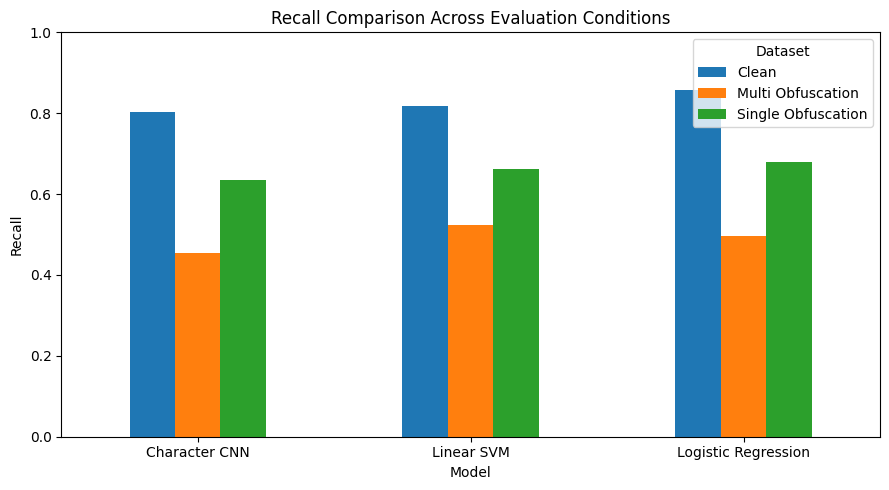

In [ ]:
import matplotlib.pyplot as plt

recall_plot = overall_comparison.pivot(
    index="model",
    columns="dataset",
    values="recall"
)

recall_plot.plot(kind="bar", figsize=(9, 5))

plt.title("Recall Comparison Across Evaluation Conditions")
plt.ylabel("Recall")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

plot recall degradation

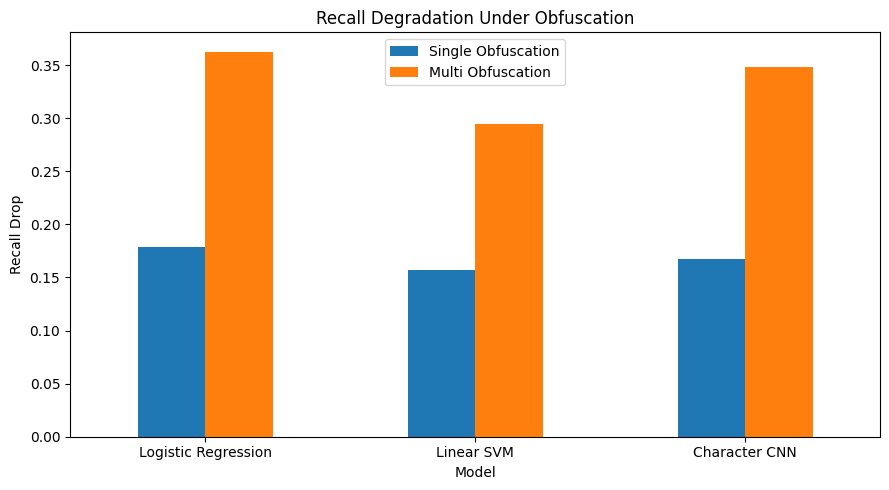

In [ ]:
drop_plot = robustness_df.set_index("model")[
    ["single_recall_drop", "multi_recall_drop"]
]

drop_plot.plot(kind="bar", figsize=(9, 5))

plt.title("Recall Degradation Under Obfuscation")
plt.ylabel("Recall Drop")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend([
    "Single Obfuscation",
    "Multi Obfuscation"
])
plt.tight_layout()
plt.show()

comparison graph

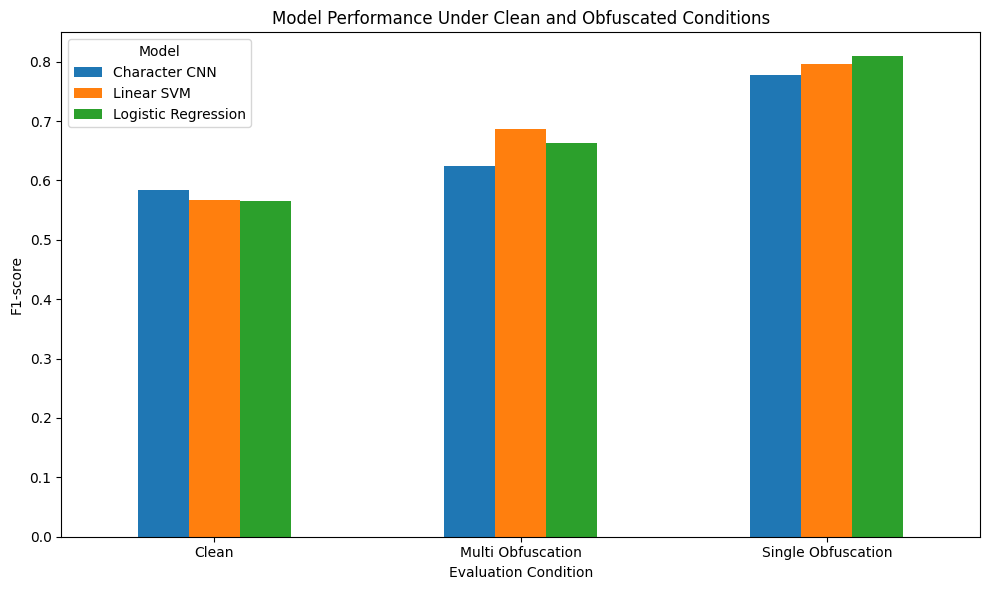

In [ ]:
import matplotlib.pyplot as plt

pivot = comparison_results.pivot(
    index="dataset",
    columns="model",
    values="f1"
)

pivot.plot(
    kind="bar",
    figsize=(10,6)
)

plt.ylabel("F1-score")
plt.xlabel("Evaluation Condition")
plt.title(
    "Model Performance Under Clean and Obfuscated Conditions"
)

plt.xticks(rotation=0)
plt.legend(title="Model")

plt.tight_layout()
plt.show()

compare performance severity

In [ ]:
cnn_severity_results = []

for severity in ["low", "medium", "high"]:

    subset = single_df[
        single_df["severity"].str.lower() == severity
    ]

    metrics = evaluate_cnn(
        cnn_model,
        subset,
        text_col="obfuscated_text"
    )

    cnn_severity_results.append({
        "model": "Character CNN",
        "n_samples": len(subset),
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "severity": severity
    })

cnn_severity = pd.DataFrame(cnn_severity_results)

display(cnn_severity.round(4))

,model,n_samples,precision,recall,f1,severity
0,Character CNN,13473,1.0,0.7076,0.8288,low
1,Character CNN,13360,1.0,0.6324,0.7748,medium
2,Character CNN,13193,1.0,0.5307,0.6934,high


severity-level recall drop

In [ ]:
cnn_clean_recall = cnn_clean_metrics["recall"]

In [ ]:
cnn_severity["recall_drop"] = (
    cnn_clean_recall - cnn_severity["recall"]
)

display(cnn_severity.round(4))

,model,n_samples,precision,recall,f1,severity,recall_drop
0,Character CNN,13473,1.0,0.7076,0.8288,low,0.0955
1,Character CNN,13360,1.0,0.6324,0.7748,medium,0.1707
2,Character CNN,13193,1.0,0.5307,0.6934,high,0.2725


In [ ]:
severity_ml = ml_severity[
    ml_severity["severity"].isin(["low", "medium", "high"])
].copy()

clean_recall_lookup = {
    "Logistic Regression": ml_overall.loc[
        (ml_overall["model"] == "Logistic Regression") &
        (ml_overall["dataset"] == "Clean"),
        "recall"
    ].iloc[0],

    "Linear SVM": ml_overall.loc[
        (ml_overall["model"] == "Linear SVM") &
        (ml_overall["dataset"] == "Clean"),
        "recall"
    ].iloc[0]
}

severity_ml["recall_drop"] = severity_ml.apply(
    lambda row:
        clean_recall_lookup[row["model"]] - row["recall"],
    axis=1
)

In [ ]:
severity_comparison = pd.concat(
    [
        severity_ml[
            [
                "model",
                "n_samples",
                "precision",
                "recall",
                "f1",
                "severity",
                "recall_drop"
            ]
        ],
        cnn_severity
    ],
    ignore_index=True
)

display(
    severity_comparison
    .sort_values(["severity", "model"])
    .round(4)
)

,model,n_samples,precision,recall,f1,severity,recall_drop
8,Character CNN,13193,1.0,0.5307,0.6934,high,0.2725
3,Linear SVM,13193,1.0,0.5318,0.6943,high,0.2861
0,Logistic Regression,13193,1.0,0.5397,0.7010,high,0.3182
6,Character CNN,13473,1.0,0.7076,0.8288,low,0.0955
4,Linear SVM,13473,1.0,0.7583,0.8626,low,0.0595
1,Logistic Regression,13473,1.0,0.7942,0.8853,low,0.0637
7,Character CNN,13360,1.0,0.6324,0.7748,medium,0.1707
5,Linear SVM,13360,1.0,0.6594,0.7948,medium,0.1584
2,Logistic Regression,13360,1.0,0.6650,0.7988,medium,0.1928


In [ ]:
severity_order = ["low", "medium", "high"]

severity_comparison["severity"] = pd.Categorical(
    severity_comparison["severity"],
    categories=severity_order,
    ordered=True
)

severity_comparison = severity_comparison.sort_values(
    ["severity", "model"]
)

display(severity_comparison.round(4))

,model,n_samples,precision,recall,f1,severity,recall_drop
6,Character CNN,13473,1.0,0.7076,0.8288,low,0.0955
4,Linear SVM,13473,1.0,0.7583,0.8626,low,0.0595
1,Logistic Regression,13473,1.0,0.7942,0.8853,low,0.0637
7,Character CNN,13360,1.0,0.6324,0.7748,medium,0.1707
5,Linear SVM,13360,1.0,0.6594,0.7948,medium,0.1584
2,Logistic Regression,13360,1.0,0.6650,0.7988,medium,0.1928
8,Character CNN,13193,1.0,0.5307,0.6934,high,0.2725
3,Linear SVM,13193,1.0,0.5318,0.6943,high,0.2861
0,Logistic Regression,13193,1.0,0.5397,0.7010,high,0.3182


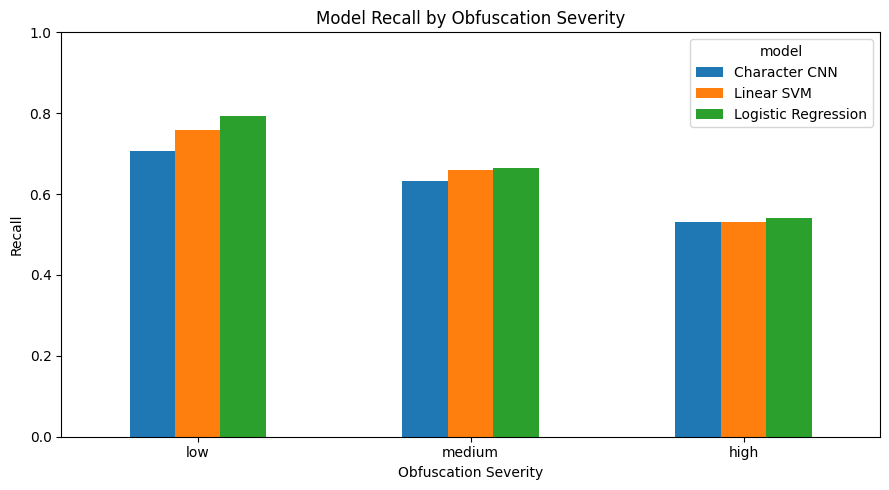

In [ ]:
severity_plot = severity_comparison.pivot(
    index="severity",
    columns="model",
    values="recall"
)

severity_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Model Recall by Obfuscation Severity")
plt.xlabel("Obfuscation Severity")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

comparison of indvidual technqiues

In [ ]:
cnn_technique_results = []

for attack in single_df["obfuscation_type"].dropna().unique():

    if attack == "clean":
        continue

    subset = single_df[
        single_df["obfuscation_type"] == attack
    ]

    metrics = evaluate_cnn(
        cnn_model,
        subset,
        text_col="obfuscated_text"
    )

    cnn_technique_results.append({
        "model": "Character CNN",
        "obfuscation_type": attack,
        "n_samples": len(subset),
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"]
    })

cnn_technique = pd.DataFrame(cnn_technique_results)

cnn_technique["recall_drop"] = (
    cnn_clean_metrics["recall"] -
    cnn_technique["recall"]
)

display(cnn_technique.round(4))

,model,obfuscation_type,n_samples,precision,recall,f1,recall_drop
0,Character CNN,character_substitution,8169,1.0,0.6286,0.7719,0.1746
1,Character CNN,spacing,7365,1.0,0.6925,0.8183,0.1107
2,Character CNN,symbolic_masking,8169,1.0,0.4961,0.6632,0.3070
3,Character CNN,misspelling,8154,1.0,0.7111,0.8311,0.0921
4,Character CNN,unicode_confusable,8169,1.0,0.5996,0.7497,0.2036


technique-level robustness

In [ ]:
cnn_attack_results = []

for attack in single_df["obfuscation_type"].dropna().unique():

    if attack == "clean":
        continue

    for severity in ["low", "medium", "high"]:

        subset = single_df[
            (single_df["obfuscation_type"] == attack) &
            (single_df["severity"].str.lower() == severity)
        ]

        if len(subset) == 0:
            continue

        metrics = evaluate_cnn(
            cnn_model,
            subset,
            text_col="obfuscated_text"
        )

        cnn_attack_results.append({
            "model": "Character CNN",
            "obfuscation_type": attack,
            "severity": severity,
            "n_samples": len(subset),
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"],
            "recall_drop":
                cnn_clean_metrics["recall"] -
                metrics["recall"]
        })

cnn_attack_results = pd.DataFrame(
    cnn_attack_results
)

display(cnn_attack_results.round(4))

,model,obfuscation_type,severity,n_samples,precision,recall,f1,recall_drop
0,Character CNN,character_substitution,low,2723,1.0,0.7106,0.8308,0.0925
1,Character CNN,character_substitution,medium,2723,1.0,0.6342,0.7762,0.1689
2,Character CNN,character_substitution,high,2723,1.0,0.5409,0.7021,0.2622
3,Character CNN,spacing,low,2585,1.0,0.7571,0.8617,0.0461
4,Character CNN,spacing,medium,2473,1.0,0.6931,0.8187,0.1101
5,Character CNN,spacing,high,2307,1.0,0.6194,0.7650,0.1837
6,Character CNN,symbolic_masking,low,2723,1.0,0.6276,0.7712,0.1755
7,Character CNN,symbolic_masking,medium,2723,1.0,0.5017,0.6681,0.3015
8,Character CNN,symbolic_masking,high,2723,1.0,0.3592,0.5285,0.4440
9,Character CNN,misspelling,low,2719,1.0,0.7389,0.8498,0.0643


In [ ]:
import pandas as pd

# LR/SVM single-obfuscation results
ml_single = pd.read_csv("ml_single_obfuscation_results.csv")

ml_overall = pd.read_csv("ml_overall_results.csv")

# clean recall for LR and SVM
clean_recall_lookup = {
    "Logistic Regression": ml_overall.loc[
        (ml_overall["model"] == "Logistic Regression") &
        (ml_overall["dataset"] == "Clean"),
        "recall"
    ].iloc[0],

    "Linear SVM": ml_overall.loc[
        (ml_overall["model"] == "Linear SVM") &
        (ml_overall["dataset"] == "Clean"),
        "recall"
    ].iloc[0]
}

# Remove clean rows
ml_technique = ml_single[
    ml_single["obfuscation_type"] != "clean"
].copy()

# Add model's clean recall
ml_technique["clean_recall"] = ml_technique["model"].map(
    clean_recall_lookup
)

# recall degradation
ml_technique["recall_drop"] = (
    ml_technique["clean_recall"] -
    ml_technique["recall"]
)

print("ml_technique created successfully!")

display(
    ml_technique[
        [
            "model",
            "obfuscation_type",
            "severity",
            "n_samples",
            "precision",
            "recall",
            "f1",
            "recall_drop"
        ]
    ].round(4)
)

ml_technique created successfully!


,model,obfuscation_type,severity,n_samples,precision,recall,f1,recall_drop
0,Logistic Regression,character_substitution,high,2723,1.0,0.4793,0.6480,0.3786
1,Logistic Regression,character_substitution,low,2723,1.0,0.8039,0.8913,0.0540
2,Logistic Regression,character_substitution,medium,2723,1.0,0.6996,0.8232,0.1583
4,Logistic Regression,misspelling,high,2717,1.0,0.7471,0.8553,0.1107
5,Logistic Regression,misspelling,low,2719,1.0,0.8371,0.9113,0.0208
6,Logistic Regression,misspelling,medium,2718,1.0,0.8039,0.8913,0.0540
7,Logistic Regression,spacing,high,2307,1.0,0.9419,0.9701,-0.0840
8,Logistic Regression,spacing,low,2585,1.0,0.8723,0.9318,-0.0145
9,Logistic Regression,spacing,medium,2473,1.0,0.9013,0.9481,-0.0435
10,Logistic Regression,symbolic_masking,high,2723,1.0,0.0051,0.0102,0.8527


In [ ]:
attack_comparison = pd.concat(
    [
        ml_technique[
            [
                "model",
                "obfuscation_type",
                "severity",
                "n_samples",
                "precision",
                "recall",
                "f1",
                "recall_drop"
            ]
        ],
        cnn_attack_results
    ],
    ignore_index=True
)

display(
    attack_comparison
    .sort_values(
        ["obfuscation_type", "severity", "model"]
    )
    .round(4)
)

,model,obfuscation_type,severity,n_samples,precision,recall,f1,recall_drop
32,Character CNN,character_substitution,high,2723,1.0,0.5409,0.7021,0.2622
15,Linear SVM,character_substitution,high,2723,1.0,0.5141,0.6791,0.3037
0,Logistic Regression,character_substitution,high,2723,1.0,0.4793,0.6480,0.3786
30,Character CNN,character_substitution,low,2723,1.0,0.7106,0.8308,0.0925
16,Linear SVM,character_substitution,low,2723,1.0,0.7657,0.8673,0.0521
1,Logistic Regression,character_substitution,low,2723,1.0,0.8039,0.8913,0.0540
31,Character CNN,character_substitution,medium,2723,1.0,0.6342,0.7762,0.1689
17,Linear SVM,character_substitution,medium,2723,1.0,0.6735,0.8049,0.1443
2,Logistic Regression,character_substitution,medium,2723,1.0,0.6996,0.8232,0.1583
41,Character CNN,misspelling,high,2717,1.0,0.6743,0.8055,0.1289


identify which attack hurts each model most

In [ ]:
worst_attacks = (
    attack_comparison
    .sort_values(
        "recall_drop",
        ascending=False
    )
)

display(
    worst_attacks[
        [
            "model",
            "obfuscation_type",
            "severity",
            "recall",
            "recall_drop"
        ]
    ].head(20).round(4)
)

,model,obfuscation_type,severity,recall,recall_drop
9,Logistic Regression,symbolic_masking,high,0.0051,0.8527
24,Linear SVM,symbolic_masking,high,0.0657,0.7521
11,Logistic Regression,symbolic_masking,medium,0.1957,0.6621
26,Linear SVM,symbolic_masking,medium,0.3331,0.4848
38,Character CNN,symbolic_masking,high,0.3592,0.4440
0,Logistic Regression,character_substitution,high,0.4793,0.3786
44,Character CNN,unicode_confusable,high,0.4734,0.3298
15,Linear SVM,character_substitution,high,0.5141,0.3037
37,Character CNN,symbolic_masking,medium,0.5017,0.3015
12,Logistic Regression,unicode_confusable,high,0.5869,0.2710


multi-obfuscation severity comparison

In [ ]:
multi_ml = ml_multi[
    ml_multi["severity"].isin(
        ["low", "medium", "high"]
    )
].copy()

In [ ]:
multi_ml["clean_recall"] = multi_ml["model"].map(
    clean_recall_lookup
)

multi_ml["recall_drop"] = (
    multi_ml["clean_recall"] -
    multi_ml["recall"]
)

In [ ]:
cnn_multi_severity_results = []

for severity in ["low", "medium", "high"]:

    subset = multi_df[
        multi_df["severity"].str.lower() == severity
    ]

    metrics = evaluate_cnn(
        cnn_model,
        subset,
        text_col="obfuscated_text"
    )

    cnn_multi_severity_results.append({
        "model": "Character CNN",
        "severity": severity,
        "n_samples": len(subset),
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "recall_drop":
            cnn_clean_metrics["recall"] -
            metrics["recall"]
    })

cnn_multi_severity = pd.DataFrame(
    cnn_multi_severity_results
)

In [ ]:
multi_severity_comparison = pd.concat(
    [
        multi_ml[
            [
                "model",
                "severity",
                "n_samples",
                "precision",
                "recall",
                "f1",
                "recall_drop"
            ]
        ],
        cnn_multi_severity
    ],
    ignore_index=True
)

display(
    multi_severity_comparison
    .sort_values(["severity", "model"])
    .round(4)
)

,model,severity,n_samples,precision,recall,f1,recall_drop
8,Character CNN,high,2572,1.0,0.3048,0.4672,0.4983
3,Linear SVM,high,2572,1.0,0.3313,0.4977,0.4866
0,Logistic Regression,high,2572,1.0,0.2811,0.4388,0.5768
6,Character CNN,low,2672,1.0,0.6078,0.7561,0.1954
4,Linear SVM,low,2672,1.0,0.6961,0.8208,0.1217
1,Logistic Regression,low,2672,1.0,0.7126,0.8322,0.1453
7,Character CNN,medium,2628,1.0,0.4452,0.6161,0.3580
5,Linear SVM,medium,2628,1.0,0.5350,0.6971,0.2828
2,Logistic Regression,medium,2628,1.0,0.4836,0.6520,0.3742


In [ ]:
final_comparison = robustness_df.copy()

final_comparison.columns = [
    "Model",
    "Clean Recall",
    "Single Recall",
    "Single ΔRecall",
    "Multi Recall",
    "Multi ΔRecall"
]

display(final_comparison.round(4))

,Model,Clean Recall,Single Recall,Single ΔRecall,Multi Recall,Multi ΔRecall
0,Logistic Regression,0.8579,0.6793,0.1785,0.4952,0.3627
1,Linear SVM,0.8178,0.6613,0.1565,0.5231,0.2947
2,Character CNN,0.8032,0.6356,0.1676,0.4545,0.3486


In [ ]:
overall_comparison.to_csv(
    "cnn_lr_svm_overall_comparison.csv",
    index=False
)

robustness_df.to_csv(
    "cnn_lr_svm_recall_robustness.csv",
    index=False
)

severity_comparison.to_csv(
    "cnn_lr_svm_severity_comparison.csv",
    index=False
)

attack_comparison.to_csv(
    "cnn_lr_svm_attack_comparison.csv",
    index=False
)

multi_severity_comparison.to_csv(
    "cnn_lr_svm_multi_severity_comparison.csv",
    index=False
)

print("All comparison files saved.")

All comparison files saved.


In [ ]:
from google.colab import files

files.download("cnn_lr_svm_overall_comparison.csv")
files.download("cnn_lr_svm_recall_robustness.csv")
files.download("cnn_lr_svm_severity_comparison.csv")
files.download("cnn_lr_svm_attack_comparison.csv")
files.download("cnn_lr_svm_multi_severity_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>